### Code to numerically solve the 1d model for solvent concentration

This code is written for a moving domain.

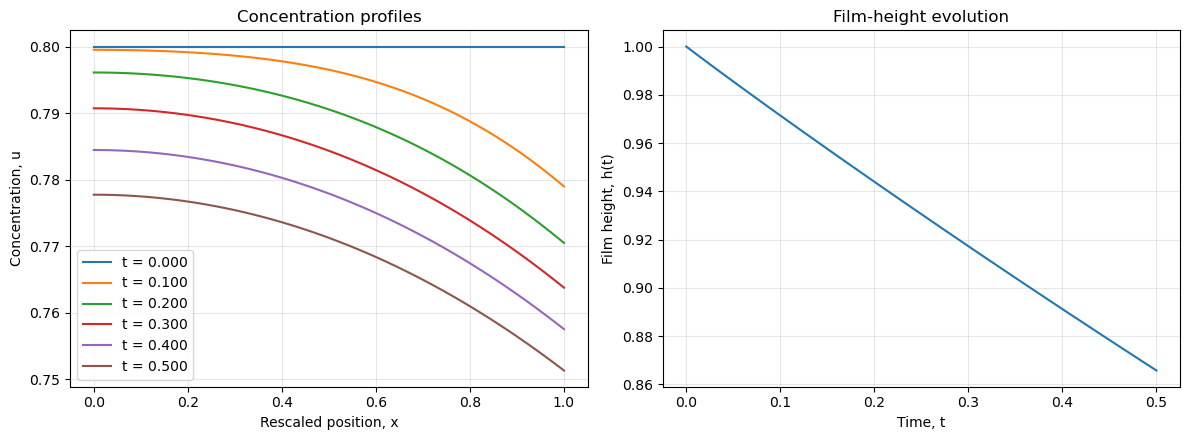

N = 100, dx = 0.01, Nt = 50000, dt = 1e-05


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# define physical parameters
Pe = 1
delta = 2
a = 2
phi_e = 0.5

# initial conditions
h_0 = 1
phi_0 = 0.8

# define diffusivity functions
def D(u):
    return (1-delta)*u**a + delta

def D_prime(u):
    return a*(1-delta)*u**(a-1)


def F(u, h, dh_dt, N, Pe, delta, a, u_e, x, dx, D, D_prime):
    F = np.zeros(N+1) # preallocate soln array
    
    # derived ghost point expressions
    u_ghost1 = u[1]
    u_ghost2 = u[N-1] - ((2*Pe*dx*h)/D(u[N]))*(1-u[N])*(u[N]- u_e)
    
    # on substrate boundary
    F[0] = (x[0]/h)*((u[1]-u_ghost1)/(2*dx))*(dh_dt) + (1/(Pe*h**2))* (D(u[0])*(u[1] - 2*u[0] +u_ghost1)/dx**2 + D_prime(u[0])*((u[1]-u_ghost1)/(2*dx))**2)
    
    # at free surface
    F[-1] = (x[-1]/h)*((u_ghost2 - u[-2])/(2*dx))*(dh_dt) + (1/(Pe*h**2))* (D(u[-1])*(u_ghost2 - 2*u[-1] +u[-2])/dx**2 + D_prime(u[-1])*((u_ghost2 - u[-2])/(2*dx))**2)
    
    # interior grid points
    # for i in range(1, N):
        # F[i] = (1/Pe)* (D(u[i])*(u[i+1] - 2*u[i] +u[i-1])/dx**2 + D_prime(u[i])*((u[i+1] - u[i-1])/(2*dx))**2)
    F[1:N] = (x[1:N]/h)*((u[2:N+1] - u[0:N-1])/(2*dx))*(dh_dt) + (1/(Pe*h**2)) * (D(u[1:N]) * (u[2:N+1] - 2*u[1:N] + u[0:N-1]) / dx**2+ D_prime(u[1:N]) * ((u[2:N+1] - u[0:N-1]) / (2*dx))**2)
    return F
    
    
def euler_method(F, tspan, u_0, h_i, Nt, N, Pe, delta, a, u_e, x, dx, D, D_prime):

    t0, tf = tspan
    dt = (tf - t0) / Nt
    t = np.linspace(t0, tf, Nt + 1)

    # store solns
    u_sol = np.zeros((Nt + 1, len(u_0)))
    h_sol = np.zeros(Nt + 1)

    # ics
    u_sol[0] = u_0
    h_sol[0] = h_i

    for n in range(Nt):
        # current soln
        u = u_sol[n]
        h = h_sol[n]

        # film-height evoln
        dh_dt = -(u[-1] - u_e)

        # ypdate u using the current h and dh/dt
        u_sol[n + 1] = u + dt * F(u, h, dh_dt, N, Pe, delta, a, u_e, x, dx, D, D_prime)

        # update film thickness
        h_sol[n + 1] = h + dt * dh_dt

    return t, u_sol, h_sol

# spatial domain
N = 100
a, b = [0, 1] # rescaled domain
x = np.linspace(0, 1, N+1) # gridpoints
dx = x[1] - x[0]

# ic
u_0 = np.full(N+1, phi_0) #as to not write u_0 as u_0

# initial trial run: conservative diffusion-based dt estimate at h=1 is ~2.5e-5.
# choose dt=1e-5 and final time 0.1 for a first short run.
tspan = (0.0, 0.5)
dt = 1e-5
Nt = int(round((tspan[1] - tspan[0]) / dt))

t, u_sol, h_sol = euler_method(F, tspan, u_0, h_0, Nt, N, Pe, delta, a, phi_e, x, dx, D, D_prime)

# generated:

# plot concentration profiles at selected times and film height
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

profile_indices = np.linspace(0, Nt, 6, dtype=int)
for idx in profile_indices:
    axes[0].plot(x, u_sol[idx], label=f"t = {t[idx]:.3f}")
axes[0].set_xlabel("Rescaled position, x")
axes[0].set_ylabel("Concentration, u")
axes[0].set_title("Concentration profiles")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t, h_sol)
axes[1].set_xlabel("Time, t")
axes[1].set_ylabel("Film height, h(t)")
axes[1].set_title("Film-height evolution")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"N = {N}, dx = {dx:.4g}, Nt = {Nt}, dt = {t[1]-t[0]:.4g}")

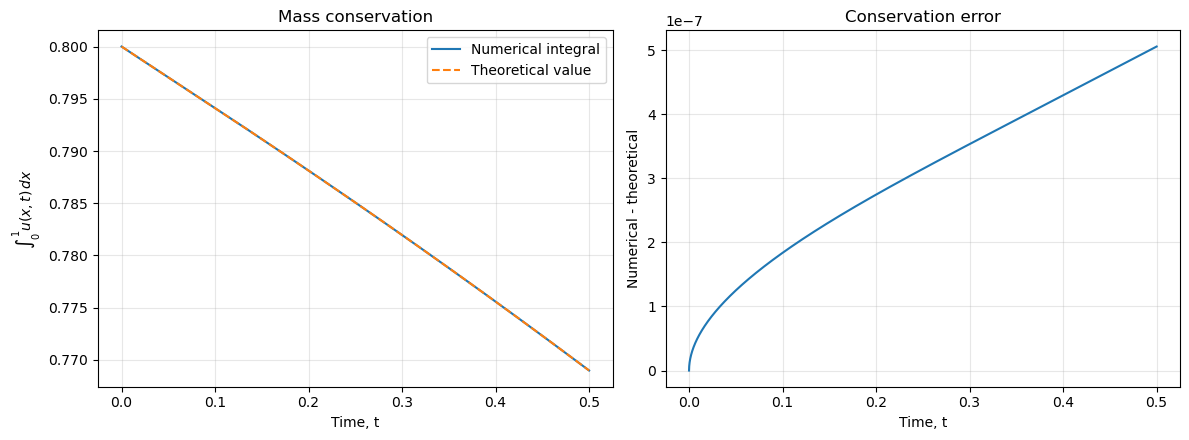

Initial numerical integral: 0.80000000
Initial theoretical value:  0.80000000
Final numerical integral:   0.76898969
Final theoretical value:    0.76898919
Maximum absolute error:     5.056564e-07


In [7]:
# verifying scheme using conservation of total solute mass

# numerical integral of u(x,t) at every timestep
M_num = np.trapz(u_sol, x=x, axis=1) # analytical soln

# theoretical integral from the conservation relation
M_theory = 1 - (1 - phi_0) / h_sol # using h_sol from numerical soln

# abs error in the conservation relation
mass_error = M_num - M_theory

# generated:

# plot numerical and theoretical mass
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(t, M_num, label="Numerical integral")
axes[0].plot(t, M_theory, "--", label="Theoretical value")
axes[0].set_xlabel("Time, t")
axes[0].set_ylabel(r"$\int_0^1 u(x,t)\,dx$")
axes[0].set_title("Mass conservation")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(t, mass_error)
axes[1].set_xlabel("Time, t")
axes[1].set_ylabel("Numerical - theoretical")
axes[1].set_title("Conservation error")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Initial numerical integral: {M_num[0]:.8f}")
print(f"Initial theoretical value:  {M_theory[0]:.8f}")
print(f"Final numerical integral:   {M_num[-1]:.8f}")
print(f"Final theoretical value:    {M_theory[-1]:.8f}")
print(f"Maximum absolute error:     {np.max(np.abs(mass_error)):.6e}")